## Research Question: What factors influence college admission rates?
This project researches what university characteristics predict how selective a school is. Specifically, variables like standardized test scores, tuition, enrollment size, school ownership type, and geographic region relate to acceptance rate.

## What This Code Does:
This notebook collects college admissions data using the U.S. Department of Education College Scorecard API. The code sends requests to the API to retrieve data on U.S. colleges and collects the information on admission rates and standardized test scores. It then combines all retrieved data into a single dataset and saves the dataset locally as a CSV file. To run the notebook, you need an API key from https://api.data.gov/signup/ 

In [19]:
import requests
import pandas as pd
import os
import time

output_dir = "../data/raw"
os.makedirs(output_dir, exist_ok=True)

output_path = os.path.join(output_dir, "college_admissions.csv")


# Set your free API key (https://api.data.gov/signup/) as an environment variable before running:
#   export SCORECARD_API_KEY="your_key_here"
API_KEY = os.environ.get("SCORECARD_API_KEY")
if not API_KEY:
    raise ValueError("Set the SCORECARD_API_KEY environment variable first.")

all_data = []
page = 0

fields = ",".join([
    "school.name",
    "school.state",
    "school.ownership",
    "school.region_id",
    "latest.admissions.admission_rate.overall",
    "latest.admissions.sat_scores.average.overall",
    "latest.admissions.act_scores.midpoint.cumulative",
    "latest.admissions.applicants",
    "latest.admissions.enrolled",
    "latest.cost.tuition.in_state",
    "latest.cost.tuition.out_of_state",
    "latest.student.size",
    "latest.student.demographics.median_hh_income",
    "latest.completion.rate_suppressed.overall"
])

while True:
    url = "https://api.data.gov/ed/collegescorecard/v1/schools"
    
    params = {
    "api_key": API_KEY,
    "fields": fields,
    "per_page": 100,
    "page": page
}

    response = requests.get(url, params=params)
    data = response.json()

    results = data.get("results", [])
    
    if not results:
        break

    all_data.extend(results)
    print(f"Downloaded page {page}")

    page += 1
    time.sleep(0.2)

df = pd.json_normalize(all_data)

output_path = os.path.join(output_dir, "college_admissions.csv")
df.to_csv(output_path, index=False)

print(f"\nSaved dataset to: {output_path}")
print(f"Shape: {df.shape}")

Downloaded page 0
Downloaded page 1
Downloaded page 2
Downloaded page 3
Downloaded page 4
Downloaded page 5
Downloaded page 6
Downloaded page 7
Downloaded page 8
Downloaded page 9
Downloaded page 10
Downloaded page 11
Downloaded page 12
Downloaded page 13
Downloaded page 14
Downloaded page 15
Downloaded page 16
Downloaded page 17
Downloaded page 18
Downloaded page 19
Downloaded page 20
Downloaded page 21
Downloaded page 22
Downloaded page 23
Downloaded page 24
Downloaded page 25
Downloaded page 26
Downloaded page 27
Downloaded page 28
Downloaded page 29
Downloaded page 30
Downloaded page 31
Downloaded page 32
Downloaded page 33
Downloaded page 34
Downloaded page 35
Downloaded page 36
Downloaded page 37
Downloaded page 38
Downloaded page 39
Downloaded page 40
Downloaded page 41
Downloaded page 42
Downloaded page 43
Downloaded page 44
Downloaded page 45
Downloaded page 46
Downloaded page 47
Downloaded page 48
Downloaded page 49
Downloaded page 50
Downloaded page 51
Downloaded page 52
Dow

## Step 2: Data Cleaning

This section prepares the raw data for modeling:
- Selects relevant columns and renames them for readability
- Maps numeric ownership codes to descriptive labels (Public, Private nonprofit, Private for-profit)
- Drops rows missing critical variables: admission rate, tuition, ownership, region, and state
- One-hot encodes categorical variables (state, ownership, region) so they can be used in regression — `drop_first=True` avoids multicollinearity by dropping one dummy per group
- Drops the school name column since it is a unique identifier, not a predictor

The baseline (omitted) categories are: the first state alphabetically, Private_for_profit ownership, and region 0.

In [20]:
df = pd.read_csv("../data/raw/college_admissions.csv")

cols = [
    "school.name",
    "school.state",
    "school.ownership",
    "latest.admissions.admission_rate.overall",
    "latest.admissions.sat_scores.average.overall",
    "latest.admissions.act_scores.midpoint.cumulative",
    "latest.cost.tuition.in_state",
    "latest.student.size",
    "school.region_id"
]
df = df[cols]

df = df.rename(columns={
    "school.name": "name",
    "school.state": "state",
    "school.ownership": "ownership",
    "latest.admissions.admission_rate.overall": "admission_rate",
    "latest.admissions.sat_scores.average.overall": "sat_avg",
    "latest.admissions.act_scores.midpoint.cumulative": "act_avg",
    "latest.cost.tuition.in_state": "tuition",
    "latest.student.size": "size",
    "school.region_id": "region"
})

df["ownership"] = df["ownership"].map({
    1: "Public",
    2: "Private_nonprofit",
    3: "Private_for_profit"
})

print("Missing ownership after mapping:", df["ownership"].isna().sum())

print("Ownership categories (alphabetical = drop order):", sorted(df["ownership"].dropna().unique()))
print("Region values (smallest = baseline):", sorted(df["region"].dropna().unique()))

print("\nShape before targeted dropna:", df.shape)
print("Missing values per column:\n", df.isna().sum())

critical_cols = ["admission_rate", "tuition", "ownership", "region", "state"]
df = df.dropna(subset=critical_cols)

print("\nShape after targeted dropna:", df.shape)
print("Missing values after targeted drop:\n", df.isna().sum())

df = pd.get_dummies(df, columns=["state", "ownership", "region"], drop_first=True)

df = df.drop(columns=["name"])

print("\nDescriptive statistics:")
print(df[["admission_rate", "tuition", "sat_avg", "act_avg", "size"]].describe())

os.makedirs("../data/clean", exist_ok=True)
df.to_csv("../data/clean/college_model_ready.csv", index=False)

print("\nFinal shape:", df.shape)
print(df.head())

Missing ownership after mapping: 0
Ownership categories (alphabetical = drop order): ['Private_for_profit', 'Private_nonprofit', 'Public']
Region values (smallest = baseline): [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]

Shape before targeted dropna: (6322, 9)
Missing values per column:
 name                 0
state                0
ownership            0
admission_rate    4395
sat_avg           5284
act_avg           5349
tuition           2660
size               735
region               0
dtype: int64

Shape after targeted dropna: (1801, 9)
Missing values after targeted drop:
 name                0
state               0
ownership           0
admission_rate      0
sat_avg           769
act_avg           845
tuition             0
size                0
region              0
dtype: int64

Descriptive statistics:
       admission_rate       tuition      sat_avg     act_avg           size
count     1801.

## Step 3: Exploratory Visualizations

Before building a model, we visualize the relationships between admission rate and key predictors.

**SAT Scores vs Admission Rate:**
There is a negative relationship between SAT Scores and admission rate. As average SAT scores increase, admission rates tend to fall. Schools with SAT averages above 1400 are almost all below a 0.4 admission rate, suggesting that high test scores are strongly associated with selectivity. The relationship fans out at lower SAT ranges, suggesting test scores alone don't fully determine selectivity for less selective schools.

**Tuition vs Admission Rate:**
The relationship here is weaker and has more noise. A large cluster of schools at low tuition (under $10,000) spans the full range of admission rates, which are likely community colleges and open-admission public schools. At higher tuition levels, the spread narrows a little, but there are highly selective and less selective schools at every price point, which explains why tuition ranked lower than state and ownership type in the regression.

**Distribution of Admission Rates:**
The distribution is pretty right-skewed, with the majority of schools admitting 70% or more of applicants. True selective schools (admission rate below 0.3) are a small number of institutions. This means the model is trying to explain a dataset where most schools are relatively open-access, which makes predicting the outliers at the low end more difficult.

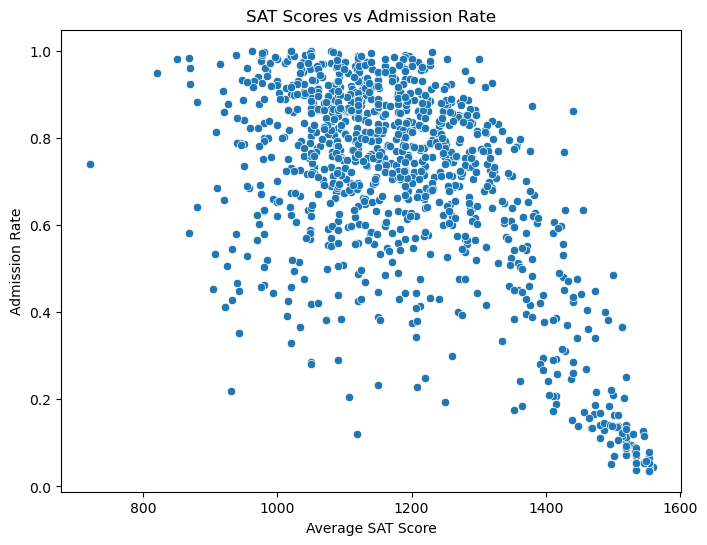

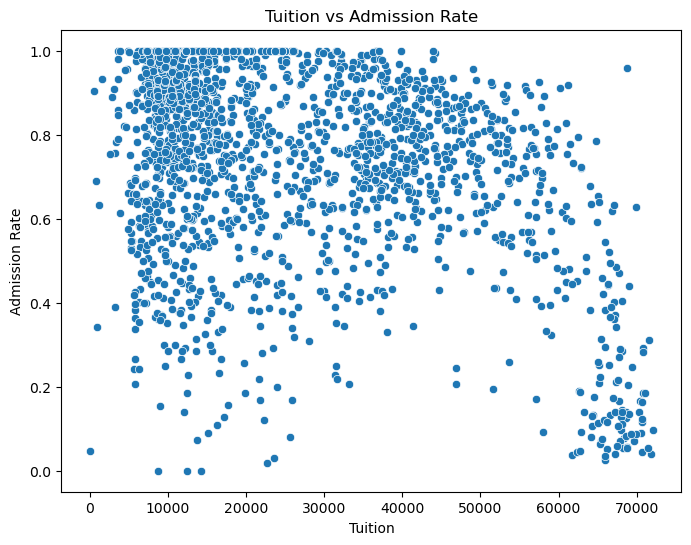

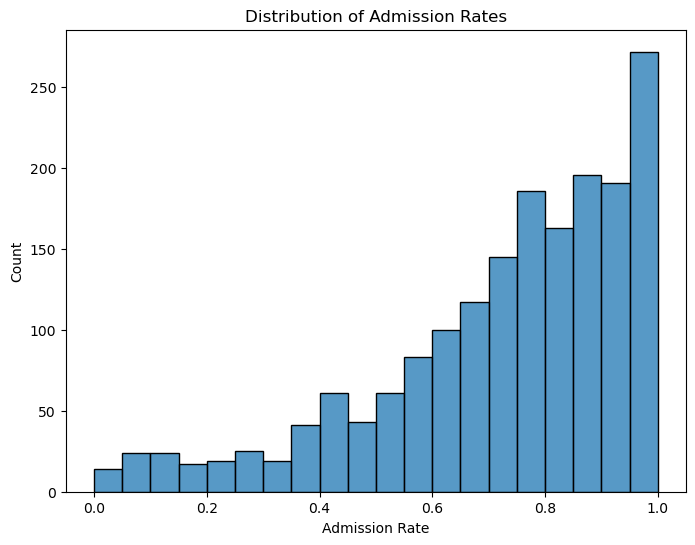

In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Scatterplot: SAT vs Admission Rate
plt.figure(figsize=(8,6))
sns.scatterplot(data=df, x='sat_avg', y='admission_rate')
plt.title("SAT Scores vs Admission Rate")
plt.xlabel("Average SAT Score")
plt.ylabel("Admission Rate")
plt.show()

# Scatterplot: Tuition vs Admission Rate
plt.figure(figsize=(8,6))
sns.scatterplot(data=df, x='tuition', y='admission_rate')
plt.title("Tuition vs Admission Rate")
plt.xlabel("Tuition")
plt.ylabel("Admission Rate")
plt.show()

# Histogram of admission rates
plt.figure(figsize=(8,6))
sns.histplot(df['admission_rate'], bins=20)
plt.title("Distribution of Admission Rates")
plt.xlabel("Admission Rate")
plt.ylabel("Count")
plt.show()

### Correlation Matrix

The heatmap below shows how strongly each pair of numeric variables is related. A value close to 1 means two variables tend to move up together, where -1 means when one goes up, the other goes down, and 0 means there is little to no relationship.

**Key takeaways:**

- **SAT avg and admission rate: -0.6** — This is the strongest relationship in the matrix. Schools with higher average SAT scores are significantly more selective. This is the clearest in the data.
- **Tuition and admission rate: -0.36** — A moderate negative relationship. Higher tuition is associated with lower admission rates, but the effect is weaker than test scores, probably because tuition varies for not related to selectivity.
- **SAT avg and tuition: 0.62** — These two are strongly correlated with each other, meaning schools with high test scores also tend to charge more. This means we need to be careful interpreting their individual coefficients in the regression.
- **Size and admission rate: -0.054** — there is basically no linear relationship. Enrollment size alone tells us very little about how selective a school is.
- **Size and tuition: -0.18** — Larger schools tend to charge slightly less, consistent with large public universities having lower tuition than smaller private schools.

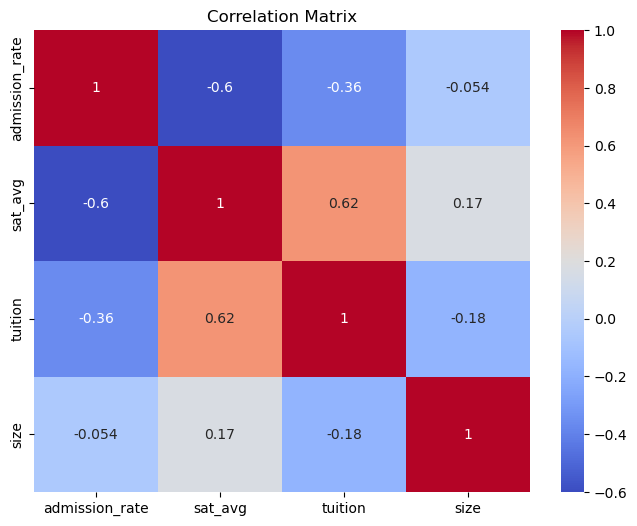

In [22]:
corr_columns = ['admission_rate', 'sat_avg', 'tuition', 'size']

correlation_matrix = df[corr_columns].corr()

plt.figure(figsize=(8,6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm')
plt.title("Correlation Matrix")
plt.show()

## Step 4: Linear Regression Model

I used Ordinary Least Squares (OLS) linear regression to model admission rate as a function of all available features. Linear regression is appropriate here because the target variable (admission rate) is continuous, coefficients are interpretable, and the research question is explanatory, not just predictive.

The dataset is split 80/20 into training and test sets. The model is fit on the training set and evaluated on the held-out test set to assess out-of-sample performance. Schools missing SAT or ACT scores are dropped since linear regression does not handle missing values natively.

In [23]:
df = df.dropna(subset=['admission_rate', 'sat_avg', 'act_avg', 'tuition', 'size'])

feature_cols = [c for c in df.columns if c != 'admission_rate']

X = df[feature_cols]
y = df['admission_rate']

assert X.isna().sum().sum() == 0, "NaNs still present in X!"

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

## Step 5: Model Results

### Performance Metrics
- **R-squared: 0.372** — The model shows that about 37% of the variation in admission rates across institutions. While statistically meaningful, this modest fit hints that the features available in the College Scorecard data only partially capture what makes selectivity.
- **Mean Squared Error: 0.034** — The average squared prediction error. Taking the square root gives an average error of about 18 percentage points, meaning if a school's true admission rate is 50%, the model might predict anywhere from 32% to 68%. This is a pretty big range, which aligns well with the spread visible in the actual vs. predicted plot.

In [24]:
r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)

print("Model Performance")
print(f"R-squared: {r2}")
print(f"Mean Squared Error: {mse}")

Model Performance
R-squared: 0.3720327255989755
Mean Squared Error: 0.03394979460088894


### Regression Coefficients

Each coefficient represents the estimated change in admission rate for a one-unit increase in that feature, holding all other features constant. For dummy variables, the coefficient represents the difference relative to the baseline category.

**Most influential features:**

- **State effects dominate the top 15.** Maine (ME) has the largest single coefficient at -0.209, meaning schools in Maine admit about 21 percentage points fewer applicants than the baseline state, all else equal. Washington DC (-0.156) and Hawaii (-0.121) also are selective and bring their state average down.
- **Ownership type matters significantly.** Public schools have an admission rate about 15 percentage points lower than the baseline (Private for-profit), and Private nonprofit schools are about 14 points lower.


Top 15 Regression Coefficients by Absolute Value
                    Feature  Coefficient
                   state_ME    -0.209132
                   state_DC    -0.155648
           ownership_Public    -0.152335
ownership_Private_nonprofit    -0.135546
                   state_HI    -0.120849
                   state_WA     0.115483
                   state_FL    -0.105741
                   state_NV    -0.096611
                   state_OR     0.094258
                   state_OK    -0.087639
                   state_UT     0.086042
                   state_ID    -0.075986
                   state_LA    -0.074849
                   state_VA     0.070208
                   state_NH     0.068910


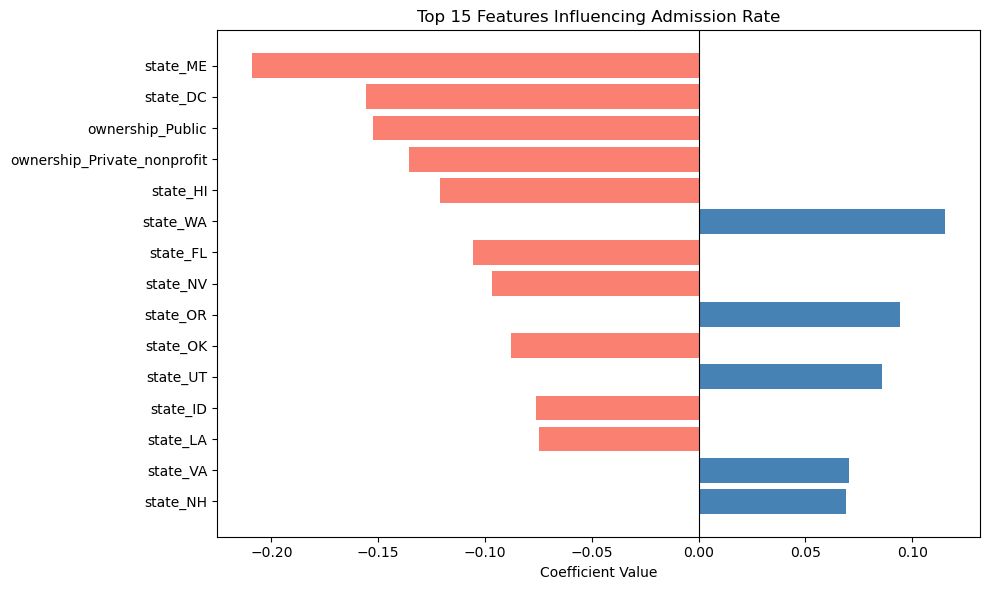

In [15]:
# Show the 15 features with the largest absolute effect on admission rate.
coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_
})

coefficients['Abs_Coefficient'] = coefficients['Coefficient'].abs()
top_coefs = coefficients.sort_values('Abs_Coefficient', ascending=False).head(15)

print("\nTop 15 Regression Coefficients by Absolute Value")
print(top_coefs[['Feature', 'Coefficient']].to_string(index=False))

# Bar chart of top coefficients
plt.figure(figsize=(10, 6))
colors = ['steelblue' if c > 0 else 'salmon' for c in top_coefs['Coefficient']]
plt.barh(top_coefs['Feature'], top_coefs['Coefficient'], color=colors)
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel("Coefficient Value")
plt.title("Top 15 Features Influencing Admission Rate")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

### Actual vs. Predicted Admission Rates

The scatter plot below compares the model's predictions to the true admission rates on the test set. Points on the red dashed line represent perfect predictions.

**Key observations:**

- **The model performs best in the middle range (0.5–0.9 actual admission rate),** where points cluster close to the reference line. This makes sense given that the distribution of admission rates is heavily skewed toward higher values, so the model has more training examples in this range.
- **The model struggles most at low admission rates (below 0.4).** Points in this region are above the reference line, meaning the model consistently overpredicts admission rates for highly selective schools, and it predicts them as less selective than they actually are. This is a known limitation of linear regression on skewed data and suggests that the features available don't fully show what makes a school highly selective.
- **There is significant vertical spread throughout,** The model shows the general trend but leaves some individual variation unexplained.

Overall the plot confirms that the model is useful for understanding broad patterns in selectivity.

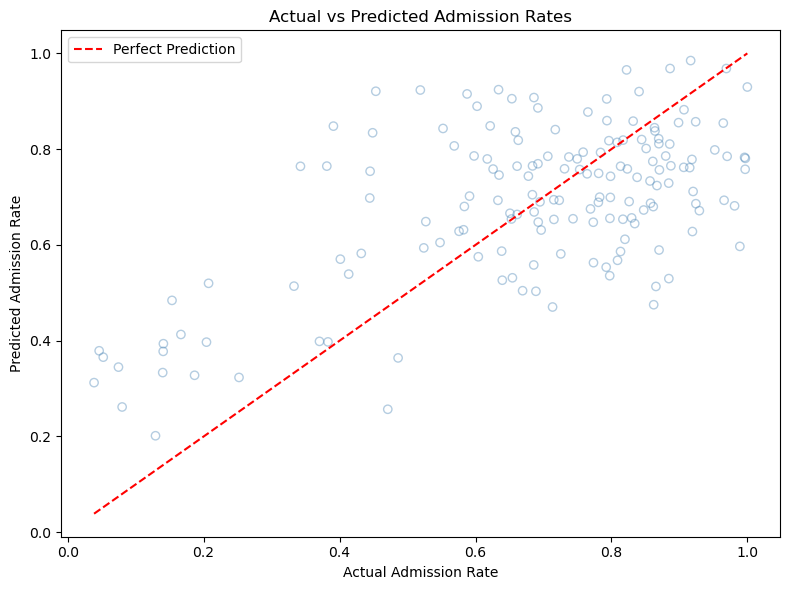

In [16]:
# Actual vs Predicted plot with reference line
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.4, edgecolors='steelblue', facecolors='none')

# Perfect prediction line — points on this line = exact predictions
min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())
plt.plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=1.5, label='Perfect Prediction')

plt.xlabel("Actual Admission Rate")
plt.ylabel("Predicted Admission Rate")
plt.title("Actual vs Predicted Admission Rates")
plt.legend()
plt.tight_layout()
plt.show()

## Step 6: Conclusions

This analysis used OLS linear regression to examine what institutional factors predict college admission rates using data from the U.S. College Scorecard API.

**Model Performance:**
The model has an R-squared of 0.372, meaning it explains roughly 37% of the variation in admission rates across institutions. While statistically meaningful, the modest fit suggests that important predictors of selectivity, like how prestigious a college is, endowment size, or applicant yield, are not captured in the College Scorecard data. The MSE of 0.034 indicates an average prediction error of approximately 18 percentage points, which is substantial given that admission rates range from 0 to 1. These results suggest that while test scores, tuition, and school type are correlated with selectivity, they alone are not sufficient to fully predict how selective a school will be.

**Key findings:**
- Standardized test scores (SAT/ACT) show a strong negative association with admission rates. Schools with higher average scores tend to be more selective, as expected.
- Tuition correlates with selectivity, though the direction varies by institution type; elite private schools often charge high tuition and admit very few applicants.
- School ownership type and location contribute to explaining differences in selectivity across institutions.

**Limitations:**
- Schools that do not report SAT or ACT scores are excluded from the model, which may bias results toward institutions that emphasize standardized testing.
- The model explains variation across institutions but does not establish causation.

**Future work** could include additional variables like the faculty-to-student ratio to improve predictive power.